Part I - Constructing the Kalman Filter: From Model to Real-Time Tracking

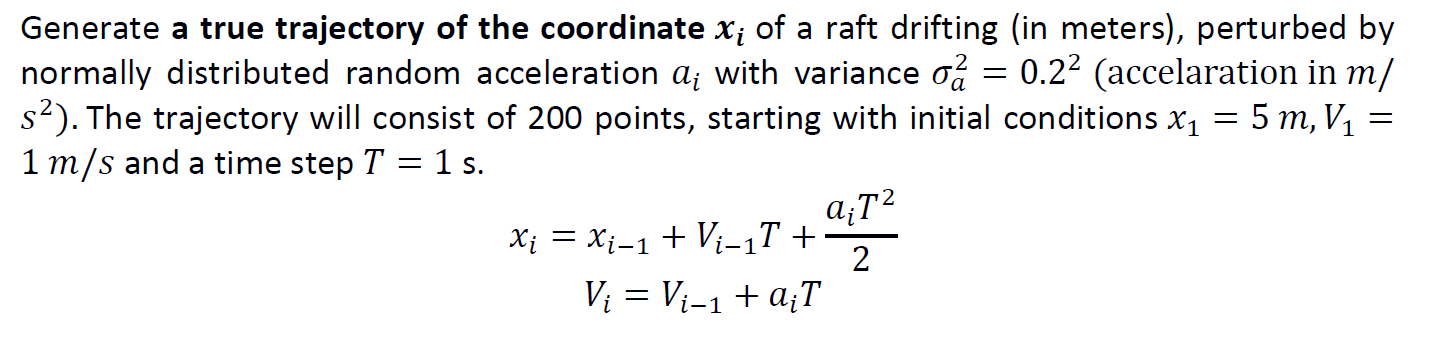

In [53]:
import numpy as np
from matplotlib import pyplot as plt

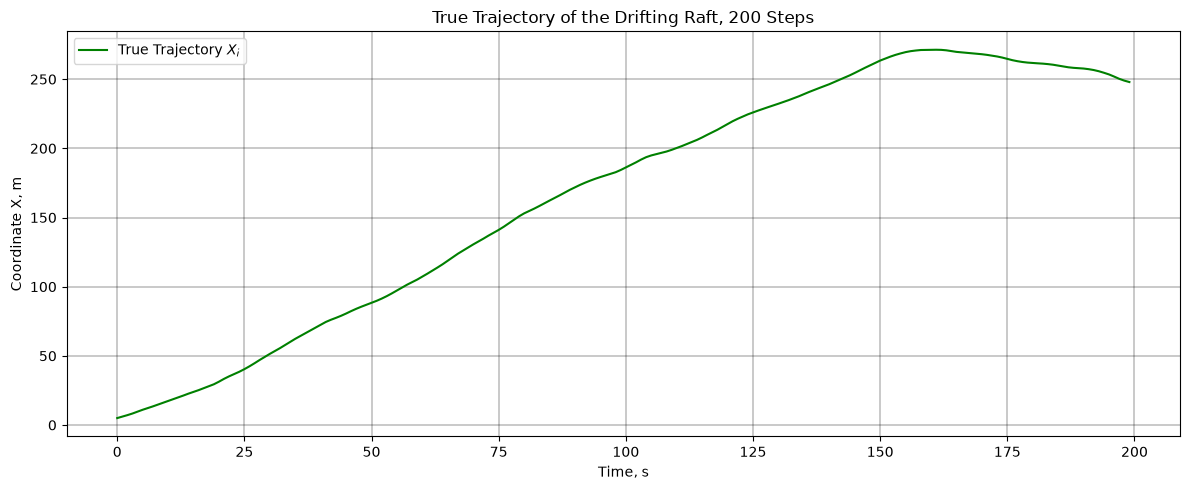

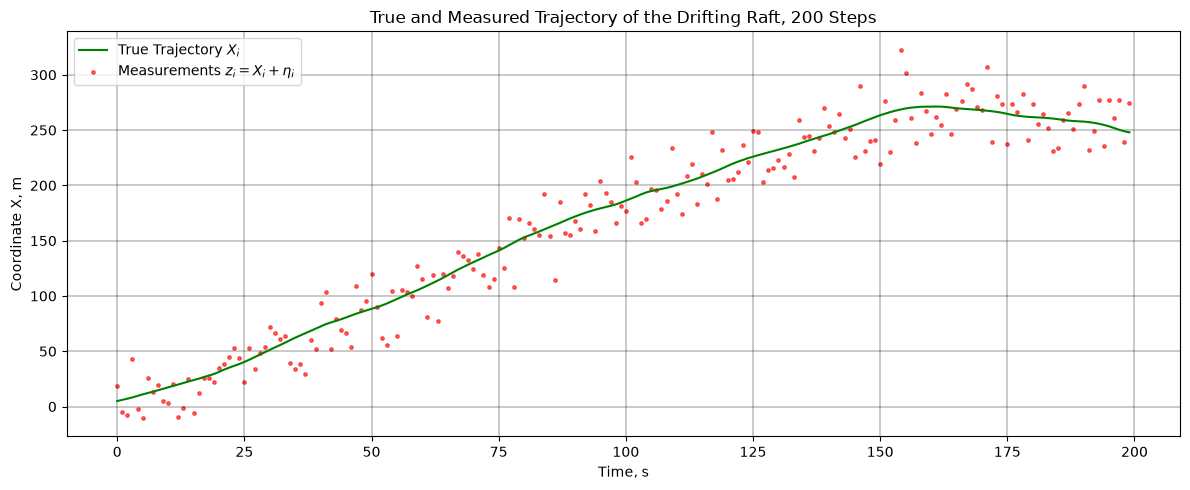

In [54]:
#generating a true tragectory of a raft drifting with a random acceleration
# save generated trajectories so the whole team works on the same data
from pathlib import Path

output_dir = Path("common_files")
output_dir.mkdir(parents=True, exist_ok=True)

# constants for trajectory modelling of the drifting raft
SIZE = 200
INITIAL_COORDINATE_M = 5
INITIAL_VELOCITY_M_S = 1
T = 1

VARIANCE_A = 0.2**2
SIGMA_A = np.sqrt(VARIANCE_A)

VARIANCE_ETA = 20**2
SIGMA_ETA = np.sqrt(VARIANCE_ETA)

# a function to generate a true trajectory of a drifting raft using the random acceleration model
def generate_true_trajectory(size, init_coord, init_velocity, sigma_a, t):
    traj_points = np.zeros(size)
    velocity_points = np.zeros(size)
    traj_points[0] = init_coord
    velocity_points[0] = init_velocity

    for i in range(1, size):
        acceleration = np.random.normal(loc=0.0, scale=sigma_a)
        traj_points[i] = traj_points[i-1] + velocity_points[i-1] * t + acceleration * t**2 / 2
        velocity_points[i] = velocity_points[i-1] + acceleration * t

    return traj_points, velocity_points

# a function to generate measured trajectory points based on the true trajectory
def generate_measured_trajectory(true_trajectory, sigma_eta):
    measured_trajectory = true_trajectory.copy()
    return measured_trajectory + np.random.normal(0.0, sigma_eta, size=measured_trajectory.size)

# a function to plot a true trajectory
def plot_true_trajectory(true_traj, title, step_size=1):
    steps = np.arange(true_traj.size * step_size, step = step_size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# a function to plot a true trajectory and measured points
def plot_true_vs_measured(true_traj, measured_traj, title, step_size=1):
    steps = np.arange(true_traj.size * step_size, step = step_size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i$")
    ax.scatter(steps, measured_traj, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# a function to plot a true trajectory, measured points and the filtered estimate
def plot_filter_results(true_traj, measured_traj, estimated_traj, title, step_size=1):
    steps = np.arange(true_traj.size * step_size, step = step_size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i$")
    ax.scatter(steps, measured_traj, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
    ax.plot(steps, estimated_traj, color="blue", linewidth=1.5, label="Kalman Filter Estimate $\\hat{x}_{i,i}$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# generate the trajectories 
#true_trajectory_raft, true_velocity_raft = generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, SIGMA_A, T)
#measured_trajectory_raft = generate_measured_trajectory(true_trajectory_raft, SIGMA_ETA)

# save the trajectories (uncomment only after checking the plots)
#np.savetxt(output_dir / "true_trajectory_raft.txt", true_trajectory_raft)
#np.savetxt(output_dir / "true_velocity_raft.txt", true_velocity_raft)
#np.savetxt(output_dir / "measured_trajectory_raft.txt", measured_trajectory_raft)

# load the trajectories shared within the team
true_trajectory_raft = np.loadtxt(output_dir / "true_trajectory_raft.txt")
true_velocity_raft = np.loadtxt(output_dir / "true_velocity_raft.txt")
measured_trajectory_raft = np.loadtxt(output_dir / "measured_trajectory_raft.txt")

# plot the trajectories
plot_true_trajectory(true_trajectory_raft, "True Trajectory of the Drifting Raft, 200 Steps", step_size=T)
plot_true_vs_measured(true_trajectory_raft, measured_trajectory_raft, "True and Measured Trajectory of the Drifting Raft, 200 Steps", step_size=T)

Representing the dynamical system in state space 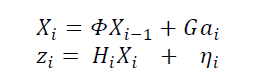

In [55]:
# state-space model of the drifting raft
# transition matrix Phi
PHI = np.array([[1, T],
                [0, 1]])

# input matrix G that defines how the random acceleration a_i influences the state vector
G = np.array([[T**2 / 2],
              [T]])

# observation matrix H that relates the measurement vector to the state vector 
H = np.array([[1, 0]])

# covariance matrix Q of the state noise G * a_i
Q = G @ G.T * VARIANCE_A

# covariance matrix R of the measurement noise
R = np.array([[VARIANCE_ETA]])

Developing a kalman Filter includes next steps: 0. Initialization 1. Prediction 2. Filtration  

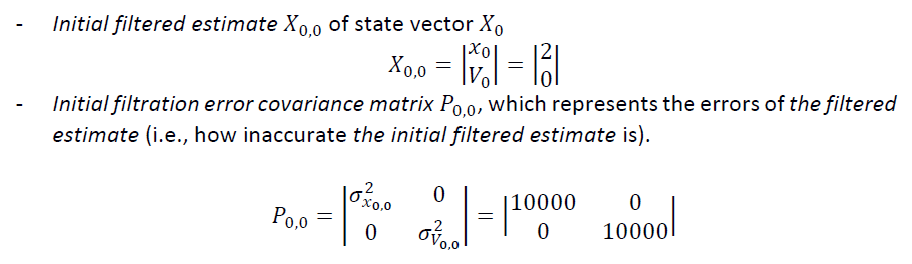

In [56]:
#setting the initial conditions for the filtered estimate and the filtration error covariance matrix
# initial filtered estimate X_{0,0} of the state vector [x, V]
X_0_0 = np.array([[2],
                  [0]])
# initial filtration error covariance matrix P_{0,0}
P_0_0 = np.array([[10000, 0],
                  [0, 10000]])


In [57]:
# Kalman filter as a function
def kalman_filter(measurements, phi, h, q, r, x_0_0, p_0_0):
    size = measurements.size

    # arrays to store the results of the filter at every step i
    x_pred = np.zeros((size, 2, 1))   # predicted state X_{i,i-1}
    p_pred = np.zeros((size, 2, 2))   # prediction error covariance P_{i,i-1}
    x_filt = np.zeros((size, 2, 1))   # filtered state X_{i,i}
    p_filt = np.zeros((size, 2, 2))   # filtration error covariance P_{i,i}
    k = np.zeros((size, 2, 1))        # filter gain K_i

    identity = np.eye(2)
    x_prev = x_0_0
    p_prev = p_0_0

    for i in range(size):
        # prediction
        x_pred[i] = phi @ x_prev
        p_pred[i] = phi @ p_prev @ phi.T + q

        # filtration
        k[i] = p_pred[i] @ h.T @ np.linalg.inv(h @ p_pred[i] @ h.T + r)
        x_filt[i] = x_pred[i] + k[i] * (measurements[i] - h @ x_pred[i])
        p_filt[i] = (identity - k[i] @ h) @ p_pred[i]

        x_prev = x_filt[i]
        p_prev = p_filt[i]

    return x_pred, p_pred, x_filt, p_filt, k

5) Plot the results, including the true trajectory, measurements, and filtered estimates of the state vector 𝑋𝑖.

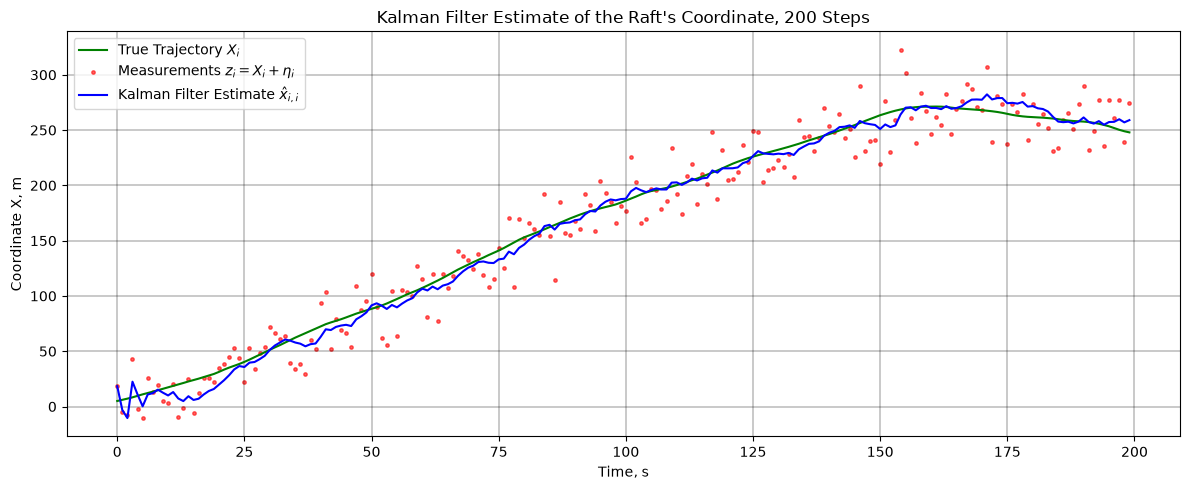

In [58]:
#Kalman filter for measured trag
x_pred, P_pred, x_filt, P_filt, K = kalman_filter(measured_trajectory_raft, PHI, H, Q, R, X_0_0, P_0_0)

# plot the true trajectory, measurements and the filtered estimate
plot_filter_results(true_trajectory_raft, measured_trajectory_raft, x_filt[:, 0, 0],
                    "Kalman Filter Estimate of the Raft's Coordinate, 200 Steps", step_size=T)

Run the filter multiple times to observe how the estimation results vary with each new trajectory.

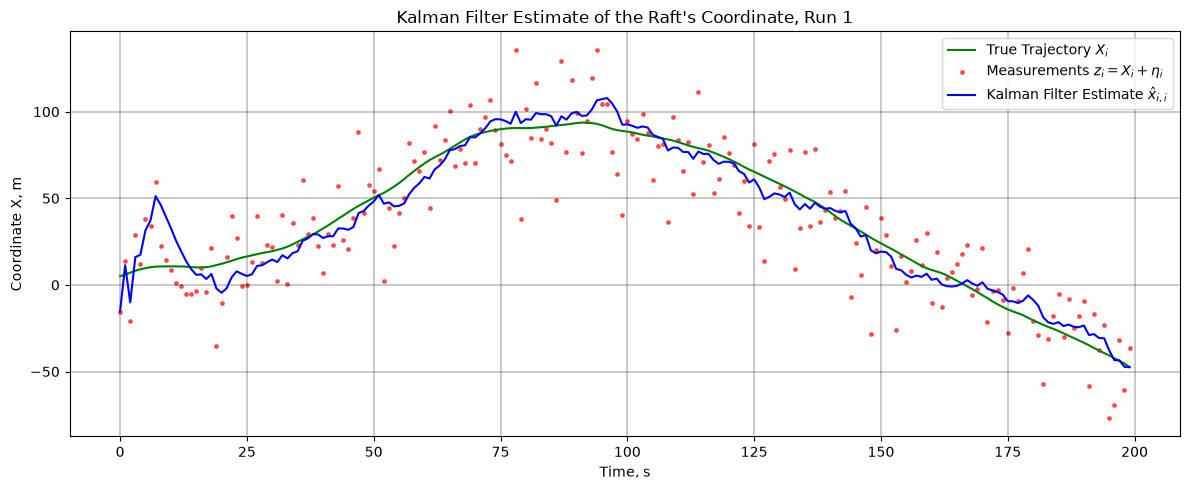

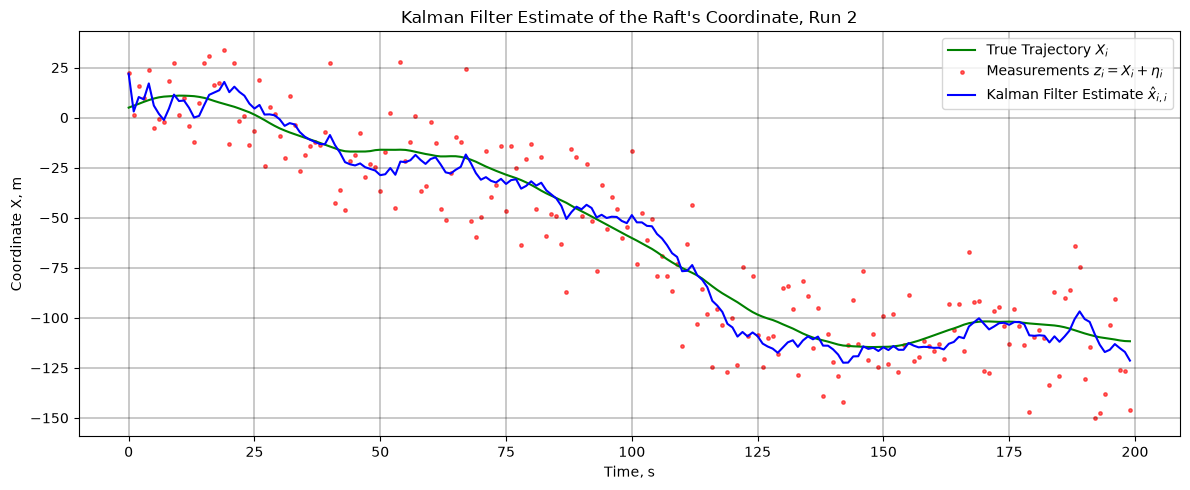

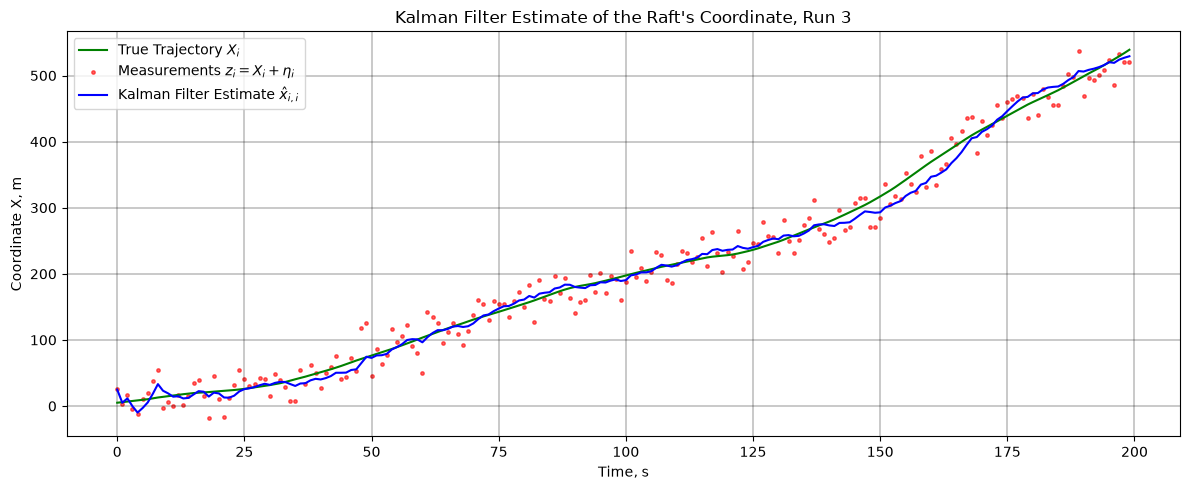

In [59]:
# run the filter several times with new trajectories and new measurements
for run in range(3):
    true_traj_run, true_vel_run = generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, SIGMA_A, T)
    measured_traj_run = generate_measured_trajectory(true_traj_run, SIGMA_ETA)
    _, _, x_filt_run, _, _ = kalman_filter(measured_traj_run, PHI, H, Q, R, X_0_0, P_0_0)

    plot_filter_results(true_traj_run, measured_traj_run, x_filt_run[:, 0, 0],
                        f"Kalman Filter Estimate of the Raft's Coordinate, Run {run + 1}", step_size=T)

6)Analysis of filter gain 𝑲𝒊 and estimation errors in the filtered state vector 𝑿𝒊.

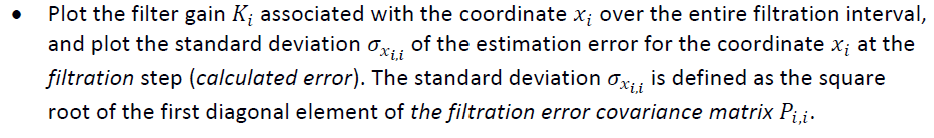

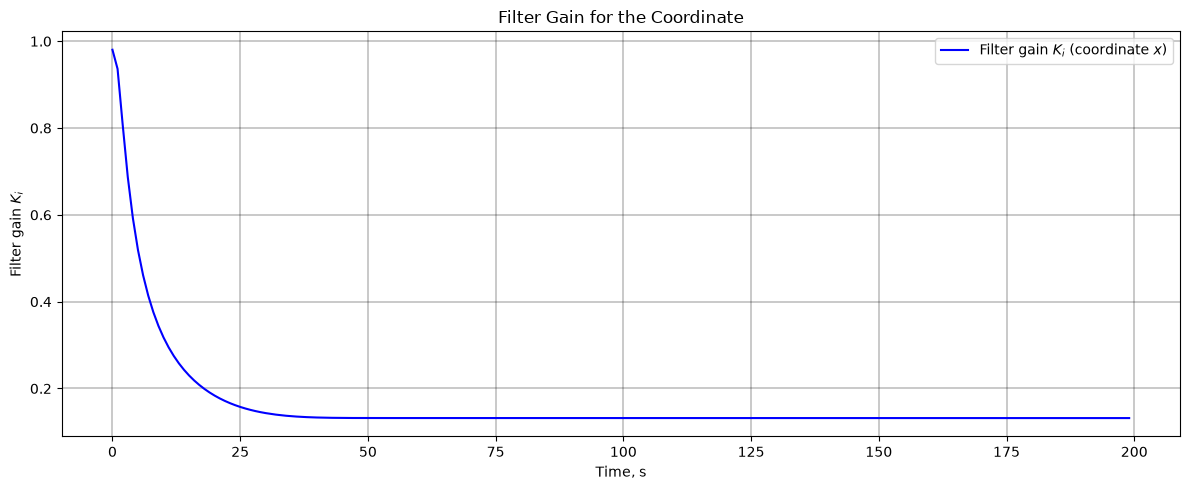

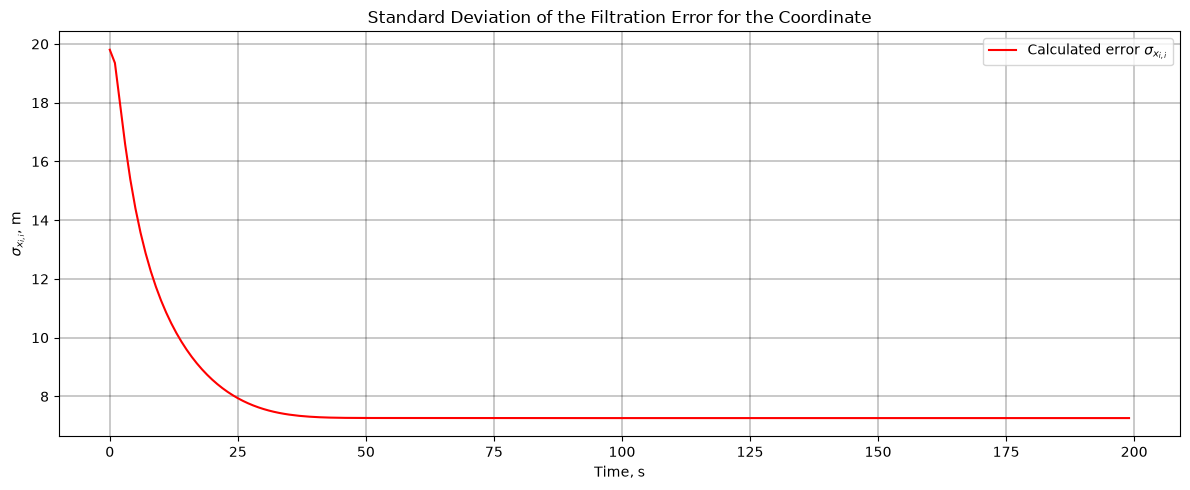

In [60]:
# filter gain for the coordinate x and standard deviation of the filtration error
steps = np.arange(SIZE * T, step = T)
K_x = K[:, 0, 0]                    # gain associated with the coordinate x
sigma_x_filt = np.sqrt(P_filt[:, 0, 0])   # sqrt of the first diagonal element of P_{i,i}

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, K_x, color="blue", linewidth=1.5, label="Filter gain $K_i$ (coordinate $x$)")
ax.set_title("Filter Gain for the Coordinate")
ax.set_xlabel("Time, s")
ax.set_ylabel("Filter gain $K_i$")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, sigma_x_filt, color="red", linewidth=1.5, label="Calculated error $\\sigma_{x_{i,i}}$")
ax.set_title("Standard Deviation of the Filtration Error for the Coordinate")
ax.set_xlabel("Time, s")
ax.set_ylabel("$\\sigma_{x_{i,i}}$, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

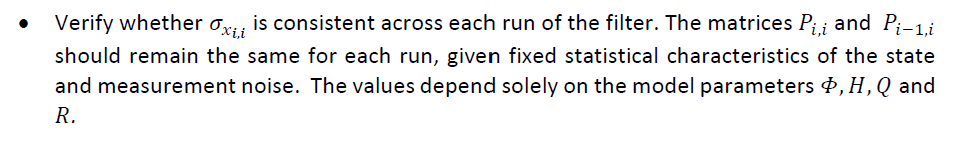

In [61]:
# run the filter on two different realizations and compare P_{i,i} and K
_, _, _, P_filt_1, K_1 = kalman_filter(generate_measured_trajectory(generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, SIGMA_A, T)[0], SIGMA_ETA), PHI, H, Q, R, X_0_0, P_0_0)
_, _, _, P_filt_2, K_2 = kalman_filter(generate_measured_trajectory(generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, SIGMA_A, T)[0], SIGMA_ETA), PHI, H, Q, R, X_0_0, P_0_0)

print(np.allclose(P_filt_1, P_filt_2), np.allclose(K_1, K_2))

True True


не читала)))  Consistency across runs. For two different realizations of the trajectory and measurements, the matrices $P_{i,i}$ and the gains $K_i$ coincide (np.allclose returns True for both). The filtration error covariance and the gain are computed from $\Phi$, $H$, $Q$, $R$ and $P_{0,0}$ only; they do not depend on the measurements $z_i$ or on the true trajectory. Therefore the calculated error $\sigma_{x_{i,i}}$ can be computed in advance, before any measurements are received.

Convergence. The gain for the coordinate decreases from about 0.98 at the first step and reaches a constant value of about 0.13 after roughly 40–50 s; the standard deviation $\sigma_{x_{i,i}}$ decreases from about 20 m to about 7.3 m and stays there. After this moment new measurements no longer improve the accuracy of the estimate: in the presence of random accelerations the raft’s motion cannot be predicted exactly, so there is a limit of accuracy that the filter cannot go below. At this stage the filter becomes stationary and a constant gain can be used instead of recomputing it at every step.

Dimension of the gain. $K_i$ has dimension $n \times m$, where $n = 2$ is the dimension of the state vector and $m = 1$ is the dimension of the measurement vector, so here it is a $2 \times 1$ matrix.

Predictions of future states of the drifting raft.

In [62]:
# predictions m-1 steps ahead from the filtered estimate X_{i,i}
M_PRED = 7

# transition matrix over m-1 steps: Phi multiplied by itself m-1 times
PHI_M = np.linalg.matrix_power(PHI, M_PRED - 1)

# X_{i+m-1,i} = Phi_{i+m-1,i} * X_{i,i} for every step i
x_pred_m = np.zeros((SIZE, 2, 1))
for i in range(SIZE):
    x_pred_m[i] = PHI_M @ x_filt[i]

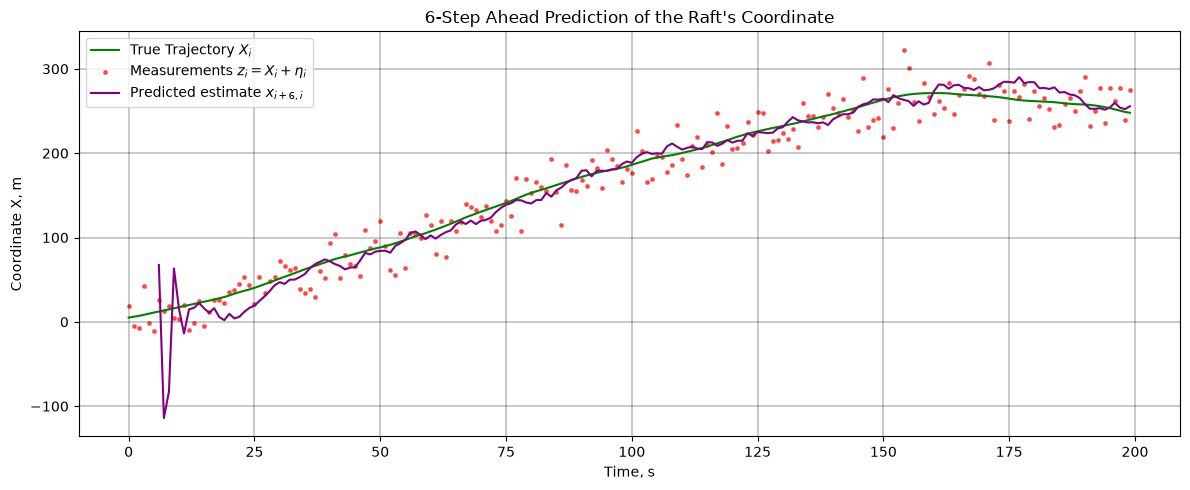

In [63]:
steps = np.arange(SIZE * T, step = T)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_raft, color="green", linewidth=1.5, label="True Trajectory $X_i$")
ax.scatter(steps, measured_trajectory_raft, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
ax.plot(steps[M_PRED - 1:], x_pred_m[:SIZE - (M_PRED - 1), 0, 0], color="purple", linewidth=1.5,
        label=f"Predicted estimate $x_{{i+{M_PRED - 1},i}}$")
ax.set_title(f"{M_PRED - 1}-Step Ahead Prediction of the Raft's Coordinate")
ax.set_xlabel("Time, s")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

The predicted estimate $x_{i+6,i}$ follows the general shape of the true trajectory, but it is noisier than the filtered estimate $x_{i,i}$. This happens because the prediction is $x_{i,i} + 6T\,V_{i,i}$, so the error of the velocity estimate is multiplied by six. At the beginning of the observation interval, when the velocity estimate is still very inaccurate, the prediction deviates from the true trajectory by more than 100 m. Near the turning point of the trajectory the prediction overshoots the true trajectory, because it extrapolates the velocity estimated at step $i$, which changes randomly over the next six steps. The farther ahead we predict, the larger the prediction error becomes.